# Objetivo y metodología del modelo
Este cuaderno automatiza la selección comparativa de empresas mediante métricas fundamentales descargadas desde Yahoo Finance. El objetivo es generar un índice compuesto que permita evaluar rápidamente qué compañías muestran un perfil más atractivo según criterios de valuación (P/E, deuda, crecimiento, rentabilidad, etc.).
- Se descargan datos financieros crudos (`yfinance`) para un conjunto de tickers definidos por el usuario.
- Se limpian y transforman las métricas clave, imputando faltantes y acotando valores extremos para mantener comparabilidad.
- Se calculan indicadores complementarios como WACC, ROIC y la volatilidad del ROE, que enriquecen la evaluación de retorno vs. riesgo.
- Se normalizan las variables, se aplican los pesos calibrados y se obtiene un ranking ponderado que se exporta a CSV.
Usá este documento como guía para entender el flujo completo antes de ejecutar las celdas siguientes.

In [ ]:
import pandas as pd
import math
from datetime import datetime as _dt, timedelta as _td
from functools import lru_cache
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
try:
    import seaborn as sns
except ImportError:
    raise ImportError("Debe instalar el paquete seaborn: pip install seaborn")
try:
    import yfinance as yf
except ImportError:
    raise ImportError("Debe instalar el paquete yfinance: pip install yfinance")

Modelo Calibrado con:
-   "Market Cap": 0.05,
-   "P/E": 0.25,
-   "EPS": 0.10,
-   "EPS Growth": 0.05,
-   "Debt to Equity": 0.25,
-   "ROE": 0.05,
-   "ROEvar": 0.05,
-   "Roic/WACC": 0.20

Funciones para el ETA

In [ ]:
def _to_numeric_series(s):
    """Devuelve la serie como float, coercionando strings/objetos a NaN cuando no sean numéricos."""
    if s is None:
        return pd.Series(dtype=float)
    try:
        return pd.to_numeric(pd.Series(s), errors="coerce")
    except Exception:
        try:
            # Si ya es una Series, coercionar directamente
            return pd.to_numeric(s, errors="coerce")
        except Exception:
            return pd.Series(dtype=float)
        

def _first_valid_float(s):
    """Primero válido y finito como float, o None."""
    try:
        s = _to_numeric_series(s).dropna()
        for v in s:
            if np.isfinite(v):
                return float(v)
        return None
    except Exception:
        return None
    
def _as_float(x):
    """Convierte cualquier valor a float finito si es posible; caso contrario devuelve np.nan."""
    try:
        v = float(x)
        return v if np.isfinite(v) else np.nan
    except Exception:
        # intentá remover separadores comunes
        try:
            v = float(str(x).replace(",", "").replace(" ", ""))
            return v if np.isfinite(v) else np.nan
        except Exception:
            return np.nan
        

def _finite_or_none(x):
    """Devuelve float(x) si es finito; si no, None."""
    v = _as_float(x)
    return None if (isinstance(v, float) and not np.isfinite(v)) or pd.isna(v) else v

def _bound(x, lo=None, hi=None):
    """Acota x entre [lo, hi] si corresponde."""
    v = _as_float(x)
    if pd.isna(v):
        return np.nan
    if lo is not None:
        v = max(lo, v)
    if hi is not None:
        v = min(hi, v)
    return v

Modelo 2

In [ ]:
# ========= Helpers WACC (con chequeos)
def _latest_non_na(series):
    try:
        s = _to_numeric_series(series).dropna()
        return float(s.iloc[0]) if len(s) else None
    except Exception:
        return None


def _fetch_risk_free_rate():
    try:
        tnx = yf.Ticker("^TNX").history(period="5d", interval="1d")
        if tnx is None or tnx.empty:
            return None
        val = _as_float(tnx["Close"].iloc[-1]) / 100.0
        return _finite_or_none(val)
    except Exception:
        return None


def _compute_tax_rate(income):
    if income is None or getattr(income, "empty", True):
        return None
    tax_names = ["Income Tax Expense","Provision for Income Taxes","Tax Provision","Income Tax Expense Benefit"]
    ebt_names = ["Income Before Tax","Earnings Before Tax","Pretax Income","Income Before Tax (EBT)"]
    tax = ebt = None
    for n in tax_names:
        if n in income.index:
            tax = _latest_non_na(income.loc[n])
            if tax is not None: break
    for n in ebt_names:
        if n in income.index:
            ebt = _latest_non_na(income.loc[n])
            if ebt not in (None, 0): break
    if tax is None or ebt in (None, 0):
        return None
    return _bound(tax/ebt, 0.0, 0.40)


def _compute_kd(income, balance):
    if income is None or getattr(income, "empty", True) or balance is None or getattr(balance, "empty", True):
        return None
    # Intereses
    interest = None
    for n in ["Interest Expense","Interest Expense Non Operating","Net Interest Income"]:
        if n in income.index:
            v = _latest_non_na(income.loc[n])
            if v is not None:
                interest = abs(v); break
    if interest is None:
        return None
    # Deuda promedio
    debt_series = None
    for n in ["Total Debt","Long Term Debt","Long Term Debt And Capital Lease Obligation","Short Long Term Debt"]:
        if n in balance.index:
            s = _to_numeric_series(balance.loc[n]).dropna()
            if not s.empty:
                debt_series = s.astype(float); break
    if debt_series is None or debt_series.empty:
        return None
    avg_debt = float(debt_series.iloc[:2].mean()) if len(debt_series) >= 2 else float(debt_series.iloc[0])
    if avg_debt <= 0:
        return None
    return _bound(interest/avg_debt, 0.0, 0.20)


def _get_market_cap(t):
    # 1) info.marketCap
    try:
        info = t.info or {}
        mc = _finite_or_none(info.get("marketCap"))
        if mc is not None:
            return mc
    except Exception:
        pass
    # 2) Precio * acciones
    try:
        hist = t.history(period="1d")
        if hist is not None and not hist.empty:
            price = _as_float(hist["Close"].iloc[-1])
            sh = t.get_shares_full(start="2000-01-01")
            if sh is not None and not sh.empty:
                # intentar distintas columnas posibles
                for col in ["Shares Outstanding","Basic Shares Outstanding","Basic Average Shares"]:
                    if col in sh.columns:
                        shares = _as_float(sh[col].iloc[-1])
                        if np.isfinite(price) and np.isfinite(shares):
                            return price * shares
    except Exception:
        return None
    return None


def _get_beta(t):
    try:
        info = t.info or {}
        for k in ("beta","beta3Year","beta5Year"):
            v = _finite_or_none(info.get(k))
            if v is not None:
                return v
    except Exception:
        pass
    return None


def calcular_wacc_yahoo(ticker, mrp=0.055, rf=None):
    t = yf.Ticker(ticker)
    try: income = t.financials
    except Exception: income = None
    try: balance = t.balance_sheet
    except Exception: balance = None

    E = _get_market_cap(t)
    D = None
    if balance is not None and not balance.empty and "Total Debt" in balance.index:
        s = _to_numeric_series(balance.loc["Total Debt"]).dropna()
        if not s.empty:
            D = _finite_or_none(s.iloc[0])
    if D is None:
        D = 0.0

    beta = _get_beta(t)
    rf_ = rf if rf is not None else _fetch_risk_free_rate()
    kd = _compute_kd(income, balance)
    tax = _compute_tax_rate(income)

    notes = []
    # Defaults si faltan / no finitos
    if not np.isfinite(_as_float(rf_)):
        rf_, notes = 0.04, notes+["RF ^TNX no disponible; 4.0% por defecto"]
    if not np.isfinite(_as_float(beta)):
        beta, notes = 1.0, notes+["β no disponible; 1.0 por defecto"]
    if not np.isfinite(_as_float(kd)):
        kd, notes = 0.06, notes+["Kd no disponible; 6.0% por defecto"]
    if not np.isfinite(_as_float(tax)):
        tax, notes = 0.25, notes+["T no disponible; 25% por defecto"]
    if not np.isfinite(_as_float(E)):
        return {"Ticker": ticker, "WACC": np.nan, "WACC_Notas": "Sin Market Cap (no numérico)"}

    # Saneos finales
    E = _bound(E, 0.0, None)
    D = _bound(D, 0.0, None)
    beta = _bound(beta, -5.0, 5.0)
    rf_ = _bound(rf_, 0.0, 0.20)
    kd = _bound(kd, 0.0, 0.30)
    tax = _bound(tax, 0.0, 0.50)

    V = E + D if np.isfinite(E) and np.isfinite(D) else np.nan
    if not np.isfinite(V) or V <= 0:
        return {"Ticker": ticker, "WACC": np.nan, "WACC_Notas": "E+D inválido"}

    ke = rf_ + beta*mrp
    wacc = (E/V)*ke + (D/V)*kd*(1.0 - tax)

    return {"Ticker": ticker, "WACC": float(wacc), "WACC_Notas": "; ".join(notes)}

# ========= Helpers ROIC (con chequeos) =========
def _safe(series, key):
    try:
        return _as_float(series.get(key, np.nan))
    except Exception:
        return np.nan


def calcular_roic_yahoo(ticker):
    t = yf.Ticker(ticker)
    try: is_ = t.financials
    except Exception: is_ = pd.DataFrame()
    try: bs_ = t.balance_sheet
    except Exception: bs_ = pd.DataFrame()

    if is_.empty or bs_.empty:
        return {"Ticker": ticker, "ROIC": np.nan, "ROIC_Notas": "sin datos suficientes"}

    icols = list(is_.columns)[:2] if len(is_.columns) >= 2 else list(is_.columns)
    bcols = list(bs_.columns)[:2] if len(bs_.columns) >= 2 else list(bs_.columns)
    if not icols or not bcols:
        return {"Ticker": ticker, "ROIC": np.nan, "ROIC_Notas": "sin periodos suficientes"}

    if "Ebit" in is_.index:
        ebit = _safe(is_.loc["Ebit"], icols[0])
    elif "Operating Income" in is_.index:
        ebit = _safe(is_.loc["Operating Income"], icols[0])
    else:
        ebit = np.nan

    income_bt = _as_float(is_.loc["Income Before Tax", icols[0]]) if "Income Before Tax" in is_.index else np.nan
    tax_exp   = _as_float(is_.loc["Income Tax Expense", icols[0]]) if "Income Tax Expense" in is_.index else np.nan
    try:
        eff_tax = np.nan if (pd.isna(income_bt) or income_bt == 0 or pd.isna(tax_exp)) else tax_exp / income_bt
        eff_tax = _bound(eff_tax, 0.0, 0.35)
    except Exception:
        eff_tax = np.nan
    if np.isnan(eff_tax):
        eff_tax = 0.25

    nopat = np.nan if np.isnan(ebit) else float(ebit) * (1 - eff_tax)

    def invested_cap_at(col):
        total_debt = 0.0
        for k in ['Total Debt','Short Long Term Debt','Long Term Debt','Short Term Debt','Current Debt','Long Term Debt Noncurrent']:
            if k in bs_.index:
                val = _as_float(bs_.loc[k, col])
                if np.isfinite(val):
                    total_debt += val
        equity = _as_float(bs_.loc['Total Stockholder Equity', col]) if 'Total Stockholder Equity' in bs_.index else np.nan
        equity = 0.0 if not np.isfinite(equity) else equity
        cash   = _as_float(bs_.loc['Cash And Cash Equivalents', col]) if 'Cash And Cash Equivalents' in bs_.index else np.nan
        cash   = 0.0 if not np.isfinite(cash) else cash
        val = total_debt + equity - cash
        return max(0.0, val) if np.isfinite(val) else np.nan

    ic_vals = [invested_cap_at(c) for c in bcols]
    ic_vals = [v for v in ic_vals if np.isfinite(v)]
    ic_avg  = np.nan if len(ic_vals)==0 else float(np.mean(ic_vals))

    roic = np.nan
    if np.isfinite(ic_avg) and ic_avg != 0 and np.isfinite(nopat):
        roic = float(nopat) / float(ic_avg)

    return {"Ticker": ticker, "ROIC": roic, "ROIC_Notas": "" if np.isfinite(roic) else "ROIC no estimable"}


def _roe_quarterly_std_yahoo(ticker, max_q=8):
    """
    Desvío estándar del ROE trimestral (~2 años).
    ROE_q ≈ Net Income / Total Stockholder Equity del mismo corte trimestral.
    """
    t = yf.Ticker(ticker)
    try: q_is = t.quarterly_financials
    except Exception: q_is = pd.DataFrame()
    try: q_bs = t.quarterly_balance_sheet
    except Exception: q_bs = pd.DataFrame()

    if q_is.empty or q_bs.empty: return np.nan
    cols = list(q_is.columns)[:max_q]
    if not cols: return np.nan

    roes = []
    for c in cols:
        try:
            ni = _as_float(q_is.loc["Net Income", c]) if "Net Income" in q_is.index else np.nan
            eq = _as_float(q_bs.loc["Total Stockholder Equity", c]) if ("Total Stockholder Equity" in q_bs.index and c in q_bs.columns) else np.nan
            if np.isfinite(ni) and np.isfinite(eq) and eq != 0:
                roes.append(float(ni)/float(eq))
        except Exception:
            continue

    if len(roes) < 2: return np.nan
    return float(np.std(roes, ddof=1))

# ========= Helper: detection de emisión en CF o series de shares =========
def _any_issuance_in_past_n(df_cf, keys, n=4, threshold=1e-6):
    if df_cf is None or getattr(df_cf, 'empty', True):
        return None
    found_any_row = False
    for k in keys:
        if k in df_cf.index:
            found_any_row = True
            row = pd.to_numeric(df_cf.loc[k], errors='coerce')
            if row.dropna().empty:
                continue
            vals = np.array(row.values, dtype=float)
            vals_slice = vals[:n] if len(vals) >= 1 else vals
            if np.any(np.isfinite(vals_slice) & (vals_slice > threshold)):
                return True
    for idx in df_cf.index:
        low = str(idx).lower()
        if 'issu' in low or 'common stock' in low or 'proceeds' in low:
            found_any_row = True
            row = pd.to_numeric(df_cf.loc[idx], errors='coerce')
            if row.dropna().empty:
                continue
            vals = np.array(row.values, dtype=float)
            vals_slice = vals[:n] if len(vals) >= 1 else vals
            if np.any(np.isfinite(vals_slice) & (vals_slice > threshold)):
                return True
    return False if found_any_row else None


def exportar_lista_empresas(tickers_comparables):
    campos = {
        "Market Cap": "marketCap",
        "P/E": "trailingPE",
        "EPS": "trailingEps",
        "EPS Growth": "earningsQuarterlyGrowth",
        "Debt to Equity": "debtToEquity",
        "ROE": "returnOnEquity",
        "Dividend Yield": "dividendYield"
    }

    # descargar S&P500 (Adj Close) una vez para todos los tickers
    sp500_series = None
    try:
        sp_df = yf.download("^GSPC", start="2010-01-01", progress=False)
        if sp_df is not None and not sp_df.empty:
            sp500_series = sp_df["Adj Close"] if "Adj Close" in sp_df.columns else sp_df["Close"]
    except Exception:
        sp500_series = None

    filas = []
    issuance_keys = [
        'Common Stock Issued', 'Issuance Of Common Stock', 'Proceeds From Issuance Of Common Stock',
        'Issuance of Common Stock', 'Issuance Of Stock', 'Issuance of common stock',
        'Proceeds from issuance of common stock', 'Proceeds from issuance of shares'
    ]
    issuance_window_years = 4

    for tick in tickers_comparables:
        try:
            info = yf.Ticker(tick).info
            row = {"Ticker": tick}
            for nombre, clave in campos.items():
                row[nombre] = _as_float(info.get(clave, np.nan))

            # === Book Value / Price-to-Book (nuevo) ===
            book_val = _as_float(info.get("bookValue", np.nan))
            price = _as_float(info.get("currentPrice", info.get("regularMarketPrice", np.nan)))
            if not np.isfinite(price):
                try:
                    hist = yf.Ticker(tick).history(period="5d", actions=False)
                    if hist is not None and not hist.empty:
                        price = _as_float(hist["Close"].iloc[-1])
                except Exception:
                    price = np.nan
            pb = _as_float(info.get("priceToBook", np.nan))
            if not np.isfinite(pb) and np.isfinite(price) and np.isfinite(book_val) and book_val != 0:
                pb = float(price) / float(book_val)
            row["Book Value"] = book_val
            row["Price/Book"] = pb

            # === Dividend metrics ===
            annual_div = _as_float(info.get("dividendRate", np.nan))
            div_shield = np.nan
            if np.isfinite(annual_div) and np.isfinite(price) and price != 0:
                div_shield = float(annual_div) / float(price)
            div_growth_5y = np.nan
            try:
                divs = yf.Ticker(tick).dividends
                if isinstance(divs, (pd.Series,)) and not divs.empty:
                    divs = divs.sort_index()
                    yearly = divs.resample('Y').sum()
                    yearly = yearly[-6:]
                    if len(yearly.dropna()) >= 2:
                        yoy = yearly.pct_change().dropna()
                        last_n = yoy[-5:]
                        if len(last_n) > 0:
                            div_growth_5y = float(last_n.mean())
            except Exception:
                div_growth_5y = np.nan

            # Correlación con S&P500 desde 2010 (usa sp500_series si está disponible)
            corr_sp = np.nan
            try:
                if sp500_series is not None:
                    tdf = yf.download(tick, start="2010-01-01", progress=False)
                    if tdf is not None and not tdf.empty:
                        t_adj = tdf["Adj Close"] if "Adj Close" in tdf.columns else tdf["Close"]
                        sp_ret = sp500_series.pct_change().dropna()
                        t_ret = t_adj.pct_change().dropna()
                        common = pd.concat([t_ret, sp_ret], axis=1, join='inner')
                        if common.shape[0] >= 30:
                            corr_val = common.corr().iloc[0,1]
                            if np.isfinite(_as_float(corr_val)):
                                corr_sp = float(corr_val)
            except Exception:
                corr_sp = np.nan

            # Attach computed dividend metrics to row
            row["Dividend Rate"] = annual_div
            row["Dividend Shield"] = div_shield
            row["Dividend Growth 5Y"] = div_growth_5y
            row["Corr S&P500"] = corr_sp

            # === NUEVO: Margen Bruto (Gross Margin) ===
            gm = np.nan
            try:
                t_fin = yf.Ticker(tick)
                is_ = t_fin.financials
                if is_ is not None and not is_.empty:
                    cols_is = list(is_.columns)
                    if cols_is:
                        c0 = cols_is[0]
                        revenue = None
                        for rname in ["Total Revenue", "Revenue", "Sales", "Net Sales"]:
                            if rname in is_.index:
                                revenue = _as_float(is_.loc[rname, c0])
                                if np.isfinite(revenue):
                                    break
                        cost = None
                        for cname in ["Cost Of Goods Sold", "Cost of Goods Sold", "Cost Of Revenue", "Cost of Sales", "Cost of goods sold"]:
                            if cname in is_.index:
                                cost = _as_float(is_.loc[cname, c0])
                                if np.isfinite(cost):
                                    break
                        if np.isfinite(revenue) and revenue != 0 and np.isfinite(cost):
                            gm = (revenue - cost) / revenue
            except Exception:
                gm = np.nan
            row["Gross Margin"] = gm

            # === NUEVO: detección de emisión de acciones en últimos N años ===
            issuance_detected = None
            try:
                t_fin = yf.Ticker(tick)
                cf = None
                try:
                    cf = t_fin.cashflow
                except Exception:
                    cf = None
                issuance_detected = _any_issuance_in_past_n(cf, issuance_keys, n=issuance_window_years)

                if issuance_detected is None:
                    # fallback: buscar en series de shares si está disponible
                    sh = None
                    try:
                        sh = t_fin.get_shares_full()
                    except Exception:
                        sh = None
                    if (sh is None or getattr(sh, 'empty', True)) and hasattr(t_fin, 'get_shares_full'):
                        try:
                            sh = t_fin.get_shares_full(start=(pd.Timestamp.today() - pd.DateOffset(years=issuance_window_years+1)).strftime('%Y-%m-%d'))
                        except Exception:
                            sh = None
                    if sh is not None and not sh.empty:
                        for col in ['Shares Outstanding', 'Basic Shares Outstanding', 'Basic Average Shares']:
                            if col in sh.columns:
                                series = pd.to_numeric(sh[col].dropna(), errors='coerce')
                                if series.empty:
                                    continue
                                series = series.sort_index()
                                cutoff = pd.Timestamp.today() - pd.DateOffset(years=issuance_window_years)
                                before = series[series.index <= cutoff]
                                if not before.empty:
                                    val_old = float(before.iloc[-1])
                                else:
                                    val_old = float(series.iloc[0])
                                val_last = float(series.iloc[-1])
                                issuance_detected = (val_last > val_old * 1.001)
                                break
            except Exception:
                issuance_detected = None

            # For dashboard display we want a strict True/False; treat undetermined as False
            row["Issued Shares 4Y"] = bool(issuance_detected) if issuance_detected is not None else False

            # === NUEVO: CFO/Assets y comparación con ROA ===
            try:
                t_local = yf.Ticker(tick)
                try:
                    fin_local = t_local.financials
                except Exception:
                    fin_local = pd.DataFrame()
                try:
                    bs_local = t_local.balance_sheet
                except Exception:
                    bs_local = pd.DataFrame()
                try:
                    cf_local = t_local.cashflow
                except Exception:
                    cf_local = pd.DataFrame()

                # Net Income (latest) and Total Assets (latest) -> ROA
                roa_cur = np.nan
                if 'Net Income' in getattr(fin_local, 'index', []):
                    ni_val = _latest_non_na(fin_local.loc['Net Income'])
                else:
                    ni_val = None
                if 'Total Assets' in getattr(bs_local, 'index', []):
                    ta_val = _latest_non_na(bs_local.loc['Total Assets'])
                else:
                    ta_val = None
                if ni_val is not None and ta_val is not None and ta_val != 0:
                    try:
                        roa_cur = float(ni_val) / float(ta_val)
                    except Exception:
                        roa_cur = np.nan

                # CFO (latest) -> CFO/Assets
                possible_cfo_keys = ['Total Cash From Operating Activities','Net cash provided by operating activities','Operating Cash Flow','Cash From Operating Activities']
                cfo_val = None
                for k in possible_cfo_keys:
                    if k in getattr(cf_local, 'index', []):
                        v = _latest_non_na(cf_local.loc[k])
                        if v is not None:
                            cfo_val = v
                            break
                cfo_assets = np.nan
                if cfo_val is not None and ta_val is not None and ta_val != 0:
                    try:
                        cfo_assets = float(cfo_val) / float(ta_val)
                    except Exception:
                        cfo_assets = np.nan

                row['CFO/Assets'] = _as_float(cfo_assets)
                # boolean: True if CFO/Assets > ROA (when both finite), else False
                try:
                    if np.isfinite(_as_float(cfo_assets)) and np.isfinite(_as_float(roa_cur)):
                        row['CFO_assets_gt_ROA'] = bool(cfo_assets > roa_cur)
                    else:
                        row['CFO_assets_gt_ROA'] = False
                except Exception:
                    row['CFO_assets_gt_ROA'] = False

                # === NUEVO: Current Ratio (Current Assets / Current Liabilities) ===
                cr = np.nan
                ca_keys = ['Total Current Assets', 'Total current assets', 'TotalCurrentAssets']
                cl_keys = ['Total Current Liabilities', 'Total current liabilities', 'TotalCurrentLiabilities', 'Current Liabilities']
                ca_val = None
                cl_val = None
                for k in ca_keys:
                    if k in getattr(bs_local, 'index', []):
                        ca_val = _latest_non_na(bs_local.loc[k])
                        break
                for k in cl_keys:
                    if k in getattr(bs_local, 'index', []):
                        cl_val = _latest_non_na(bs_local.loc[k])
                        break
                # fallback: build from components
                if not np.isfinite(_as_float(ca_val)):
                    comp_ca = ['Cash And Cash Equivalents', 'Short Term Investments', 'Net Receivables', 'Inventory', 'Accounts Receivable', 'Accounts Receivable, Net']
                    vals_ca = []
                    for comp in comp_ca:
                        if comp in getattr(bs_local, 'index', []):
                            vcur = _latest_non_na(bs_local.loc[comp])
                            vals_ca.append(0.0 if not np.isfinite(_as_float(vcur)) else float(vcur))
                    if vals_ca:
                        ca_val = sum(vals_ca)
                if not np.isfinite(_as_float(cl_val)):
                    comp_cl = ['Total Current Liabilities', 'Short Long Term Debt', 'Short Term Debt', 'Current Debt', 'Accounts Payable', 'Accounts Payable, Current']
                    vals_cl = []
                    for comp in comp_cl:
                        if comp in getattr(bs_local, 'index', []):
                            vcur = _latest_non_na(bs_local.loc[comp])
                            vals_cl.append(0.0 if not np.isfinite(_as_float(vcur)) else float(vcur))
                    if vals_cl:
                        cl_val = sum(vals_cl)
                try:
                    if ca_val is not None and cl_val is not None and cl_val != 0:
                        cr = float(ca_val) / float(cl_val)
                except Exception:
                    cr = np.nan

                row['Current Ratio'] = _as_float(cr)

            except Exception:
                row['CFO/Assets'] = np.nan
                row['CFO_assets_gt_ROA'] = False
                row['Current Ratio'] = np.nan

            # Continue with previously existing calculations
            wacc = calcular_wacc_yahoo(tick)
            roic = calcular_roic_yahoo(tick)
            row["WACC (interno)"] = _as_float(wacc.get("WACC", np.nan))
            row["ROIC (interno)"] = _as_float(roic.get("ROIC", np.nan))
            row["WACC_Notas"] = wacc.get("WACC_Notas", "")
            row["ROIC_Notas"] = roic.get("ROIC_Notas", "")

            # === NUEVO: variabilidad del ROE (últimos ~2 años) ===
            row["ROEvar"] = _roe_quarterly_std_yahoo(tick)

            filas.append(row)

        except Exception as e:
            print(f"Error en {tick}: {e}")
            continue

    df = pd.DataFrame(filas)

    # Imputación para variables base
    cols_num = list(campos.keys())
    for col in cols_num:
        if col in df.columns:
            media = df[col].mean(skipna=True)
            df[col] = df[col].fillna(media)
        else:
            df[col] = np.nan

    # Ensure dividend-related columns exist and impute sensibly
    if "Dividend Rate" not in df.columns:
        df["Dividend Rate"] = np.nan
    if "Dividend Shield" not in df.columns:
        df["Dividend Shield"] = np.nan
    if "Dividend Growth 5Y" not in df.columns:
        df["Dividend Growth 5Y"] = np.nan

    # Ensure Corr S&P500 exists
    if "Corr S&P500" not in df.columns:
        df["Corr S&P500"] = np.nan

    # Ensure Gross Margin exists
    if "Gross Margin" not in df.columns:
        df["Gross Margin"] = np.nan

    # Ensure Issuance column exists
    if "Issued Shares 4Y" not in df.columns:
        df["Issued Shares 4Y"] = False

    # Ensure CFO/Assets and boolean exist
    if "CFO/Assets" not in df.columns:
        df["CFO/Assets"] = np.nan
    if "CFO_assets_gt_ROA" not in df.columns:
        df["CFO_assets_gt_ROA"] = False

    # Ensure Current Ratio exists and impute median (default 1.0)
    if "Current Ratio" not in df.columns:
        df["Current Ratio"] = np.nan
    try:
        med_cr = float(np.nanmedian(pd.to_numeric(df["Current Ratio"], errors="coerce"))) if df["Current Ratio"].notna().any() else np.nan
    except Exception:
        med_cr = np.nan
    if not np.isfinite(med_cr):
        med_cr = 1.0
    df["Current Ratio"] = pd.to_numeric(df["Current Ratio"], errors="coerce").fillna(med_cr)

    # Fill Dividend Shield with median (so it doesn't overly penalize NaNs)
    med_shield = float(np.nanmedian(pd.to_numeric(df["Dividend Shield"], errors="coerce"))) if df["Dividend Shield"].notna().any() else 0.0
    if not np.isfinite(med_shield):
        med_shield = 0.0
    df["Dividend Shield"] = pd.to_numeric(df["Dividend Shield"], errors="coerce").fillna(med_shield)

    # Dividend Growth: fill NaN with 0 (no growth / no dividends)
    df["Dividend Growth 5Y"] = pd.to_numeric(df["Dividend Growth 5Y"], errors="coerce").fillna(0.0)

    # Corr S&P500: fill NaN with 0 (no correlation calculable)
    df["Corr S&P500"] = pd.to_numeric(df["Corr S&P500"], errors="coerce").fillna(0.0)

    # Imputación segura para ROEvar (mediana del grupo)
    if "ROEvar" not in df.columns:
        df["ROEvar"] = np.nan
    med_var = float(np.nanmedian(pd.to_numeric(df["ROEvar"], errors="coerce")))
    if not np.isfinite(med_var):
        med_var = 0.0
    df["ROEvar"] = pd.to_numeric(df["ROEvar"], errors="coerce").fillna(med_var)

    # Relación Roic/WACC (winsorización + median fill)
    ratio = df["ROIC (interno)"] / df["WACC (interno)"]
    ratio = pd.to_numeric(ratio, errors="coerce").replace([np.inf, -np.inf], np.nan)
    finite_ratio = ratio[np.isfinite(ratio)]
    p95 = float(np.nanpercentile(finite_ratio, 95)) if len(finite_ratio) > 0 else np.nan
    if np.isnan(p95) or p95 <= 0: p95 = 5.0
    ratio = ratio.clip(lower=0.0, upper=p95)
    med = float(np.nanmedian(ratio)) if np.isfinite(ratio).any() else 1.0
    df["Roic/WACC"] = ratio.fillna(med)

    return df


def calcular_indice_desde_df(df):
    # Pesos calibrados solicitados (agregadas métricas de dividendos con peso 0.1 cada una)
    # Ahora incluye "Price/Book" extraído desde Yahoo Finance.
    pesos = {
        "Market Cap": 0,
        "P/E": 0.25,
        "EPS": 0.10,
        "EPS Growth": 0.05,
        "Debt to Equity": 0.20,
        "ROE": 0.05,
        "ROEvar": 0.0,
        "Roic/WACC": 0.25,
        "Gross Margin": 0.10,
        "Corr S&P500": 0.0,
        "Dividend Shield": 0.10,
        "Dividend Growth 5Y": 0,
        "Price/Book": 0.10,
        "Current Ratio": 0.15,
    }

    requeridas = list(pesos.keys())
    if "Roic/WACC" not in df.columns:
        raise ValueError("Falta la columna 'Roic/WACC'. Corré exportar_lista_empresas primero.")

    # Coerción numérica
    for c in requeridas:
        if c not in df.columns: df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")

    valores = df[requeridas].copy()

    # Min–max robusto
    col_max = valores.max()
    col_min = valores.min()
    denom = (col_max - col_min).replace(0, np.nan)
    norm = (valores - col_min) / denom
    norm = norm.fillna(0.0)

    # Penalizar donde menor es mejor (P/E, deuda, ROEvar y Price/Book)
    for col in ("P/E", "Debt to Equity", "ROEvar", "Price/Book"):
        if col in norm.columns:
            norm[col] = 1 - norm[col]

    # Ponderación
    for col, w in pesos.items():
        if col in norm.columns:
            norm[col] = norm[col] * w

    df_ind = df.copy()
    df_ind["Índice Compuesto"] = norm.sum(axis=1)
    df_orden = df_ind.sort_values("Índice Compuesto", ascending=False).reset_index(drop=True)

    # (Se eliminó la escritura automática a CSV para evitar efectos secundarios al ejecutar el notebook)

    # Incluir columna de emisión en la tabla final
    extra_cols = ["Issued Shares 4Y"] if "Issued Shares 4Y" in df_orden.columns else []
    # agregar CFO cols si existen
    if "CFO/Assets" in df_orden.columns and "CFO/Assets" not in extra_cols:
        extra_cols.append("CFO/Assets")
    if "CFO_assets_gt_ROA" in df_orden.columns and "CFO_assets_gt_ROA" not in extra_cols:
        extra_cols.append("CFO_assets_gt_ROA")
    if "Current Ratio" in df_orden.columns and "Current Ratio" not in extra_cols:
        extra_cols.append("Current Ratio")

    return df_orden[["Ticker", "Índice Compuesto"] + requeridas + extra_cols + ["WACC (interno)", "ROIC (interno)", "WACC_Notas", "ROIC_Notas"]]


In [ ]:

""" Primero se define los tickers con los cuales vas a comparar"""
if __name__ == "__main__":
    tickers = [
    # 🤖 ROBÓTICA / IA / COMPUTACIÓN CUÁNTICA
    "IONQ", "RGTI", "QBTS", "QUBT", "ARQQ", "AI", "PLTR", "ISRG",

    # 💻 SEMICONDUCTORES
    "NVDA", "AMD", "AMAT", "ASML", "AVGO", "QCOM", "ADI", "ARM", "ALAB", "LRCX", "SMH",

    # 💻 SOFTWARE / CLOUD / INTERNET
    "MSFT", "GOOGL", "META", "AAPL", "AMZN", "ORCL", "CRM", "ADBE", "NOW", "PANW",
    "CRWD", "ACN", "IBM", "INFY", "WIX", "TEAM", "BB",

    # 🚗 AUTOS ELÉCTRICOS / MOVILIDAD
    "TSLA", "NIO", "XPEV", "BIDU", "GM", "F", "HOG",

    # 🛒 E-COMMERCE
    "MELI", "BABA", "PDD", "EBAY", "GLOB",

    # 🏦 FINANZAS / BANCOS / PAGOS
    "JPM", "BAC", "GS", "MS", "C", "V", "MA", "AXP", "PYPL", "SLM", "BX",
    "AIG", "AER", "UPST", "COIN", "MSTR", "BBD", "ITUB", "NU", "ING", "AEG",

    # 🛍️ CONSUMO DISCRECIONAL
    "HD", "WMT", "TGT", "BKNG", "ABNB", "FIVE", "ANF", "DECK", "AAP",
    "DIS", "EA", "PINS", "ARCO", "ADS",

    # 🧴 CONSUMO DEFENSIVO
    "PG", "PEP", "KO", "COKE", "KHC", "IFF", "MDLZ", "SYY", "PM", "MO",
    "WBA", "ABEV", "AKO.B", "FMX",

    # ⚕️ SALUD / FARMACÉUTICA / BIOTECH
    "UNH", "PFE", "ABBV", "ABT", "AMGN", "GILD", "LLY", "BMY", "MRK",
    "AZN", "GSK", "CVS", "MOH", "DHR", "IBB",

    # ⚡ ENERGÍA
    "XOM", "CVX", "SLB", "RIG", "HAL", "BKR", "OXY", "EQNR", "VST",
    "PBR", "OLN", "OKLO", "ICLN", "FSLR",

    # 🌱 MINERÍA / METALES / LITIO
    "AEM", "NEM", "GFI", "HMY", "KGC", "HL", "SLV", "GLD", "GOLD",
    "LAC", "LAAC", "VALE", "CSNA3", "ECL",

    # ✈️ AEROESPACIAL / DEFENSA / AVIACIÓN
    "RTX", "GE", "LMT", "NOC", "HON", "AAL", "DAL", "ASR", "ASTS", "SATL",

    # 🏗️ REAL ESTATE / CONSTRUCCIÓN / INFRAESTRUCTURA
    "LEN", "GRBK", "JOE", "FLR", "KD",

    # 🌐 TELECOMUNICACIONES / MEDIOS
    "WBD", "T", "TMUS", "AMX", "NFLX", "SPOT",

    # 🧪 INDUSTRIAL / MANUFACTURA
    "GLW", "AVY", "ADP", "FI", "GT",

    # 🇧🇷 ACCIONES BRASILEÑAS
    "ABEV3", "ITUB", "BBD", "PBR", "VALE", "NU", "MGLU3", "LREN3", "CSNA3",

    # 🇲🇽 LATINOAMÉRICA
    "FMX", "ASR", "AKO.B", "ADGO",

    # 💰 CRIPTO / BLOCKCHAIN
    "RIOT", "BITF", "ETHA",

    # 📊 ETFs
    "SPY", "QQQ", "EWZ", "EWJ", "IEUR", "ACWI", "ARKK", "IWM",
    "SMH", "IBB", "XLP", "XLC", "ICLN", "SLV", "GLD", "VXX", "IJH", "IVV",
]
    df_emp = exportar_lista_empresas(tickers)
    resultado = calcular_indice_desde_df(df_emp)

    # Mostrar el Ticker como índice
    if "Ticker" in resultado.columns:
        resultado = resultado.set_index("Ticker")

    # Asegurar que no haya columnas duplicadas
    if resultado.columns.duplicated().any():
        resultado = resultado.loc[:, ~resultado.columns.duplicated()]

    # Asegurar índice único
    if resultado.index.duplicated().any():
        idx_list = [str(x) for x in resultado.index.tolist()]
        seen = {}
        new_idx = []
        for v in idx_list:
            seen[v] = seen.get(v, 0) + 1
            new_idx.append(v if seen[v] == 1 else f"{v}.{seen[v]-1}")
        resultado.index = new_idx

    import uuid
    import pandas as pd
    from IPython.display import display, HTML

    format_map = {
        "Índice Compuesto": "{:.3f}",
        "Market Cap": "{:.0f}",
        "P/E": "{:.2f}",
        "EPS": "{:.2f}",
        "EPS Growth": "{:.2f}",
        "Debt to Equity": "{:.2f}",
        "ROE": "{:.2f}",
        "ROEvar": "{:.3f}",
        "Roic/WACC": "{:.2f}",
        "WACC (interno)": "{:.3f}",
        "ROIC (interno)": "{:.3f}",
        "Dividend Shield": "{:.3%}",
        "Dividend Growth 5Y": "{:.2%}",
        "Corr S&P500": "{:.3f}",
        "Price/Book": "{:.2f}",
        "Book Value": "{:.0f}",
        "Gross Margin": "{:.2%}",
        "CFO/Assets": "{:.2%}",
        "Current Ratio": "{:.2f}",
    }

    def _fmt_cell(val, fmt):
        try:
            if pd.isna(val):
                return ""
            return fmt.format(val)
        except Exception:
            return str(val) if val is not None else ""

    def render_sortable_table(df, fmt_map=None, caption=""):
        fmt_map = fmt_map or {}
        col_headers = list(df.columns)
        tid = "tbl_" + uuid.uuid4().hex[:8]

        # Pre-format all cell values
        rows_data = []
        for idx_val, row in df.iterrows():
            cells = [_fmt_cell(row[c], fmt_map.get(c, "{}")) for c in col_headers]
            rows_data.append((str(idx_val), cells))

        ROW_BG   = "#ffffff"   # color uniforme de todas las filas
        TICK_BG  = "#f5f7fa"   # fondo de la columna Ticker (fija)
        HOVER_BG = "#eef2ff"   # hover

        css = f"""
<style>
#{tid}_wrap {{
  max-height: 650px;
  overflow: auto;
  border: 1px solid #d1d5db;
  border-radius: 10px;
  box-shadow: 0 4px 14px rgba(0,0,0,0.07);
  font-family: Segoe UI, Arial, sans-serif;
  font-size: 12.5px;
  margin: 10px 0 20px 0;
}}
#{tid} {{
  border-collapse: separate;
  border-spacing: 0;
  width: max-content;
  min-width: 100%;
  background: {ROW_BG};
}}
/* ---- encabezados fijos (sticky top) ---- */
#{tid} thead th {{
  position: sticky;
  top: 0;
  background: #111827;
  color: #f9fafb;
  padding: 9px 13px;
  text-align: center;
  white-space: nowrap;
  cursor: pointer;
  user-select: none;
  z-index: 3;
  border-bottom: 2px solid #374151;
  border-right: 1px solid #374151;
}}
/* esquina superior-izquierda (header + columna fija) */
#{tid} thead th:first-child {{
  left: 0;
  z-index: 5;
  text-align: left;
}}
#{tid} thead th:hover {{ background: #1f2937; }}
/* flechas de ordenamiento */
#{tid} thead th .sa {{ margin-left: 5px; font-size: 9px; opacity: 0.45; }}
#{tid} thead th.s-asc  .sa::after {{ content: '▲'; opacity: 1; color: #6ee7b7; }}
#{tid} thead th.s-desc .sa::after {{ content: '▼'; opacity: 1; color: #6ee7b7; }}
#{tid} thead th:not(.s-asc):not(.s-desc) .sa::after {{ content: '⇅'; }}
/* ---- celdas de datos (todas igual) ---- */
#{tid} tbody td {{
  background: {ROW_BG};
  padding: 6px 13px;
  white-space: nowrap;
  border-bottom: 1px solid #e5e7eb;
  border-right: 1px solid #e5e7eb;
  text-align: right;
  color: #111827;
}}
/* ---- columna Ticker fija (sticky left) ---- */
#{tid} tbody th {{
  position: sticky;
  left: 0;
  background: {TICK_BG};
  font-weight: 600;
  color: #1e3a5f;
  text-align: left;
  padding: 6px 13px;
  white-space: nowrap;
  border-bottom: 1px solid #e5e7eb;
  border-right: 2px solid #d1d5db;
  z-index: 2;
}}
/* hover: toda la fila cambia de color */
#{tid} tbody tr:hover td,
#{tid} tbody tr:hover th {{ background: {HOVER_BG} !important; }}
#{tid} caption {{
  caption-side: top;
  font-size: 14px;
  font-weight: 700;
  color: #1f2937;
  padding: 10px 4px 6px 4px;
  text-align: left;
}}
</style>"""

        # ── TABLE HTML ────────────────────────────────────────────────────
        thead = f'<thead><tr><th data-col="-1">Ticker<span class="sa"></span></th>'
        for ci, col in enumerate(col_headers):
            thead += f'<th data-col="{ci}">{col}<span class="sa"></span></th>'
        thead += '</tr></thead>'

        tbody_rows = []
        for idx_val, cells in rows_data:
            tds = "".join(f"<td>{c}</td>" for c in cells)
            tbody_rows.append(f"<tr><th>{idx_val}</th>{tds}</tr>")

        cap = f"<caption>{caption}</caption>" if caption else ""
        table_html = (
            f'<div id="{tid}_wrap">'
            f'<table id="{tid}">{cap}{thead}<tbody>'
            + "".join(tbody_rows)
            + "</tbody></table></div>"
        )

        # ── JAVASCRIPT (ordenamiento por clic en encabezado) ──────────────
        js = f"""
<script>
(function(){{
  var state = {{col: null, asc: true}};
  function init() {{
    var tbl = document.getElementById('{tid}');
    if (!tbl) {{ return setTimeout(init, 80); }}
    tbl.querySelectorAll('thead th').forEach(function(th) {{
      th.addEventListener('click', function() {{ sortBy(th); }});
    }});
  }}
  function sortBy(th) {{
    var tbl   = document.getElementById('{tid}');
    var tbody = tbl.querySelector('tbody');
    var col   = parseInt(th.getAttribute('data-col'));
    var asc   = (state.col === col) ? !state.asc : false;
    state = {{col: col, asc: asc}};
    tbl.querySelectorAll('thead th').forEach(function(h) {{
      h.classList.remove('s-asc','s-desc');
    }});
    th.classList.add(asc ? 's-asc' : 's-desc');
    var rows = Array.from(tbody.querySelectorAll('tr'));
    rows.sort(function(a, b) {{
      var ac = col === -1 ? a.querySelector('th') : a.querySelectorAll('td')[col];
      var bc = col === -1 ? b.querySelector('th') : b.querySelectorAll('td')[col];
      var av = ac ? ac.textContent.trim() : '';
      var bv = bc ? bc.textContent.trim() : '';
      var an = parseFloat(av.replace(/[^0-9.\-]/g,''));
      var bn = parseFloat(bv.replace(/[^0-9.\-]/g,''));
      var cmp = (!isNaN(an) && !isNaN(bn)) ? (an - bn) : av.localeCompare(bv);
      return asc ? cmp : -cmp;
    }});
    rows.forEach(function(r){{ tbody.appendChild(r); }});
  }}
  init();
}})();
</script>"""

        display(HTML(css + table_html + js))

    render_sortable_table(resultado, format_map, "Ranking fundamental Modelo 2")


<>:278: SyntaxWarning: invalid escape sequence '\-'
<>:278: SyntaxWarning: invalid escape sequence '\-'
C:\Users\nicon\AppData\Local\Temp\ipykernel_8980\2936413727.py:278: SyntaxWarning: invalid escape sequence '\-'
  </script>"""
$ADS: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$ADS: possibly delisted; no timezone found
$ADS: possibly delisted; no timezone found

1 Failed download:
['ADS']: possibly delisted; no timezone found
$ADS: possibly delisted; no price data found  (period=1d) (Yahoo error = "No data found, symbol may be delisted")
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
$WBA: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$WBA: possibly delisted; no timezone found
$WBA: possibly delisted; no timezone found

1 Failed download:
['WBA']: possibly delisted; no timezone fou

Ticker,Índice Compuesto,Market Cap,P/E,EPS,EPS Growth,Debt to Equity,ROE,ROEvar,Roic/WACC,Gross Margin,Corr S&P500,Dividend Shield,Dividend Growth 5Y,Price/Book,Current Ratio,Issued Shares 4Y,CFO/Assets,CFO_assets_gt_ROA,WACC (interno),ROIC (interno),WACC_Notas,ROIC_Notas
AEM,0.931,91961622528,17.27,10.63,1.08,1.22,0.22,0.000,20.23,58.13%,0.172,0.981%,0.00%,3.49,1.85,True,19.78%,True,0.075,6.333,,
ACN,0.924,110673698816,14.75,12.19,0.02,25.47,0.25,0.000,20.23,31.91%,0.703,3.626%,0.00%,3.54,1.21,True,17.55%,True,0.098,8.156,,
ANF,0.924,3797914880,8.08,10.46,-0.08,82.24,0.37,0.000,20.23,61.47%,0.392,2.103%,0.00%,2.71,1.36,False,17.48%,True,0.074,1.785,,
NVDA,0.914,4823327440896,40.50,4.90,0.94,7.25,1.01,0.000,20.23,71.07%,0.632,0.020%,0.00%,30.66,2.19,True,49.67%,False,0.167,10.426,,
GOOGL,0.912,4672805404672,29.42,13.11,0.81,20.03,0.39,0.000,20.23,59.65%,0.682,0.218%,0.00%,11.23,0.94,True,27.67%,True,0.112,2.274,,
KGC,0.910,35285934080,12.57,2.35,1.29,8.20,0.35,0.000,19.93,52.70%,0.192,0.508%,0.00%,4.13,2.23,True,30.30%,True,0.118,2.351,,
EQNR,0.893,98963750912,20.47,1.94,-0.34,77.09,0.12,0.000,20.23,36.23%,0.516,3.928%,0.00%,4.91,0.60,True,15.16%,True,0.007,0.354,,
PANW,0.878,146863980544,101.17,1.79,0.62,4.89,0.16,0.000,20.23,73.41%,0.461,2.103%,0.00%,13.55,0.66,True,15.76%,True,0.086,2.412,,
NOW,0.872,94014046208,54.26,1.68,0.02,20.73,0.16,0.000,17.33,77.53%,0.553,2.103%,0.00%,8.02,0.61,True,20.91%,True,0.097,1.677,,
NEM,0.848,115957587968,14.09,7.71,0.72,15.76,0.26,0.000,14.49,53.21%,0.222,0.957%,0.00%,3.34,2.00,True,18.09%,True,0.068,0.979,,


Ticker,ASML,META,MSFT,PDD,PFE,PG
Ticker,,,,,,
ASML,1.000,0.477,0.553,0.321,0.224,0.203
META,0.477,1.000,0.573,0.256,0.188,0.200
MSFT,0.553,0.573,1.000,0.260,0.298,0.356
PDD,0.321,0.256,0.260,1.000,0.051,0.047
PFE,0.224,0.188,0.298,0.051,1.000,0.358
PG,0.203,0.200,0.356,0.047,0.358,1.000


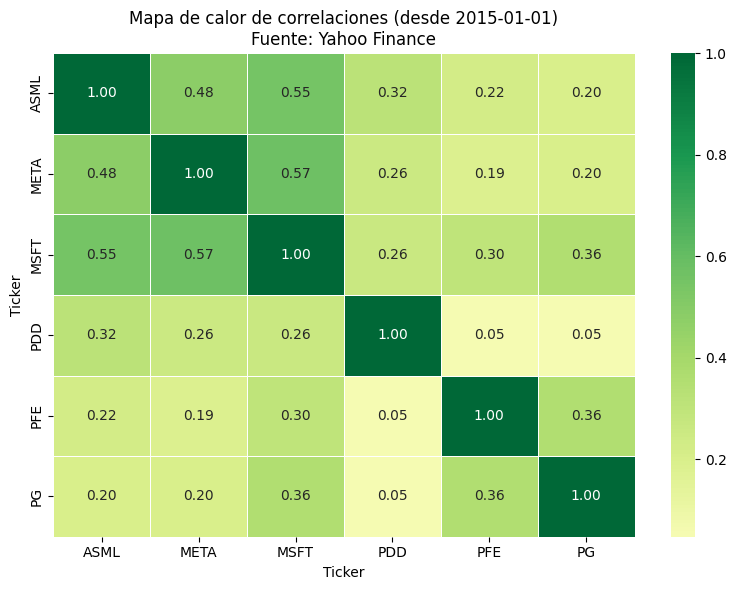

In [ ]:
# Correlación de retornos diarios desde 2015
tickers_corr = ["MSFT", "ASML", "PDD", "META", "PFE", "PG"]  # ajustá esta lista a tus necesidades
start_date = "2015-01-01"
fuente_precio = "Yahoo Finance"
panel = yf.download(tickers_corr, start=start_date, auto_adjust=False, progress=False)
if isinstance(panel.columns, pd.MultiIndex):
    precios = panel.xs("Adj Close", axis=1, level=0)
else:
    precios = panel.get("Adj Close", pd.DataFrame())
if isinstance(precios, pd.Series):
    precios = precios.to_frame()
if precios.empty:
    datos_individuales = []
    for tick in tickers_corr:
        serie_panel = yf.download(tick, start=start_date, auto_adjust=False, progress=False)
        if isinstance(serie_panel, pd.DataFrame) and "Adj Close" in serie_panel.columns:
            datos_individuales.append(serie_panel["Adj Close"].rename(tick))
    if datos_individuales:
        precios = pd.concat(datos_individuales, axis=1)
    else:
        rng = pd.date_range(start_date, periods=750, freq="B")
        rng_seed = abs(hash(tuple(tickers_corr))) % (2**32)
        rng_state = np.random.default_rng(rng_seed)
        precios = pd.DataFrame(
            rng_state.lognormal(mean=0.0002, sigma=0.01, size=(len(rng), len(tickers_corr))).cumprod(axis=0),
            index=rng,
            columns=tickers_corr
        )
        fuente_precio = "Serie simulada (sin datos descargados)"
if precios.empty:
    print("No se recuperaron precios ni se pudo generar una serie alternativa.")
else:
    retornos = precios.pct_change().dropna(how="all")
    if retornos.empty:
        print("Sin retornos calculables; revisá los datos descargados.")
    else:
        corr = retornos.corr().round(3)
        styled_corr = (
            corr.style
            .background_gradient(cmap="RdYlGn")
            .format("{:.3f}")
            .set_caption(f"Correlación diaria de retornos desde {start_date} | Fuente: {fuente_precio}")
        )
        display(styled_corr)
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax, linewidths=0.5)
        ax.set_title(f"Mapa de calor de correlaciones (desde {start_date})\nFuente: {fuente_precio}")
        plt.tight_layout()
        display(fig)
        plt.close(fig)

In [8]:

# ============================================================
#  GENERADOR DE PDF - DOCUMENTACION DE RATIOS DEL MODELO
# ============================================================
try:
    from fpdf import FPDF
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "fpdf2", "-q"])
    from fpdf import FPDF

import os
from datetime import datetime

OUTPUT_PDF = os.path.join(
    os.path.dirname(os.path.abspath("__file__")),
    "Ratios_Documentacion_Modelo.pdf"
)

# Fuentes Unicode del sistema Windows
FONT_REG  = r"C:\Windows\Fonts\arial.ttf"
FONT_BOLD = r"C:\Windows\Fonts\arialbd.ttf"
FONT_ITAL = r"C:\Windows\Fonts\ariali.ttf"
FNAME     = "Arial"

# Paleta de colores
C_TITLE  = (17,  24,  39)
C_HEAD   = (30,  58, 138)
C_SUB    = (30,  64, 175)
C_ACCENT = (37,  99, 235)
C_ROW1   = (239, 246, 255)
C_ROW2   = (255, 255, 255)
C_BORDER = (191, 219, 254)
C_BAD    = (239,  68,  68)
C_GOOD   = ( 22, 163,  74)
C_MED    = (180,  83,   9)

RATIOS = [
    {
        "nombre": "Indice Compuesto",
        "peso": "N/A (salida)",
        "fuente": "Calculado internamente",
        "formula": "Suma ponderada: S (peso_i x norm_i)",
        "desc": (
            "Puntuacion sintetica final que resume la calidad fundamental de la empresa. "
            "Cada metrica se normaliza entre 0 y 1 mediante min-max sobre el universo analizado. "
            "Para metricas donde MENOR es MEJOR (P/E, Deuda, ROEvar, Price/Book) "
            "se aplica la inversion: score = 1 - norm. "
            "El indice solo es comparable dentro del mismo universo de tickers."
        ),
        "inter": "Mayor indice => mejor perfil fundamental relativo al grupo",
        "invertido": False,
    },
    {
        "nombre": "P/E (Price to Earnings)",
        "peso": "0.25",
        "fuente": "Yahoo Finance  -  trailingPE",
        "formula": "Precio / Beneficio neto por accion (ultimos 12 meses)",
        "desc": (
            "Indica cuantas veces el mercado esta pagando las ganancias anuales de la empresa. "
            "Un P/E bajo sugiere que la accion cotiza barata respecto a sus ganancias, mientras "
            "que un P/E alto puede indicar expectativas de alto crecimiento o sobrevaluacion. "
            "Se imputa con la media del grupo cuando no esta disponible."
        ),
        "inter": "Menor P/E => mayor score  (se INVIERTE en la normalizacion)",
        "invertido": True,
    },
    {
        "nombre": "EPS (Earnings Per Share)",
        "peso": "0.10",
        "fuente": "Yahoo Finance  -  trailingEps",
        "formula": "Beneficio neto / acciones en circulacion (ultimos 12 meses)",
        "desc": (
            "Ganancias generadas por cada accion ordinaria. Refleja la rentabilidad absoluta "
            "por unidad de capital emitido. Un EPS positivo y creciente es senal de empresa "
            "saludable. Se imputa con la media del grupo cuando no esta disponible."
        ),
        "inter": "Mayor EPS => mayor score",
        "invertido": False,
    },
    {
        "nombre": "EPS Growth",
        "peso": "0.05",
        "fuente": "Yahoo Finance  -  earningsQuarterlyGrowth",
        "formula": "Variacion % del EPS respecto al mismo trimestre del anio anterior (YoY)",
        "desc": (
            "Mide el crecimiento de las ganancias por accion en el ultimo trimestre disponible "
            "comparado contra el mismo periodo del anio previo. Captura el momentum "
            "de rentabilidad reciente de la empresa."
        ),
        "inter": "Mayor crecimiento => mayor score",
        "invertido": False,
    },
    {
        "nombre": "Debt to Equity",
        "peso": "0.20",
        "fuente": "Yahoo Finance  -  debtToEquity",
        "formula": "Deuda total / Patrimonio neto",
        "desc": (
            "Mide el apalancamiento financiero. Un ratio alto indica que la empresa depende "
            "fuertemente del endeudamiento, incrementando el riesgo financiero y la sensibilidad "
            "a variaciones en tasas de interes. Se imputa con la media del grupo."
        ),
        "inter": "Menor D/E => mayor score  (se INVIERTE en la normalizacion)",
        "invertido": True,
    },
    {
        "nombre": "ROE (Return on Equity)",
        "peso": "0.05",
        "fuente": "Yahoo Finance  -  returnOnEquity",
        "formula": "Beneficio neto / Patrimonio neto promedio",
        "desc": (
            "Porcentaje de rentabilidad generado sobre el capital propio. Mide que tan "
            "eficientemente la empresa usa el dinero de los accionistas para producir ganancias. "
            "ROE alto y estable es senal de ventaja competitiva duradera."
        ),
        "inter": "Mayor ROE => mayor score",
        "invertido": False,
    },
    {
        "nombre": "ROEvar (Variabilidad del ROE)",
        "peso": "0.00 (informativo)",
        "fuente": "Calculado internamente  -  datos trimestrales Yahoo Finance",
        "formula": (
            "Desvio estandar del ROE trimestral en los ultimos ~2 anios (hasta 8 trimestres)\n"
            "ROE_q = Beneficio neto trimestral / Patrimonio neto del mismo corte"
        ),
        "desc": (
            "Captura la estabilidad de la rentabilidad sobre el capital. Una empresa con ROE "
            "muy variable puede estar sujeta a ciclos agresivos, gestion inestable o alto "
            "riesgo operativo. Se imputa con la mediana del grupo si no hay suficientes trimestres."
        ),
        "inter": "Menor variabilidad => mayor score  (se INVIERTE en la normalizacion)",
        "invertido": True,
    },
    {
        "nombre": "ROIC (interno)",
        "peso": "componente de Roic/WACC",
        "fuente": "Calculado internamente  -  estados financieros Yahoo Finance",
        "formula": (
            "ROIC = NOPAT / Capital Invertido Promedio\n"
            "NOPAT = EBIT x (1 - Tasa Efectiva de Impuestos)\n"
            "Capital Inv. = Deuda Total + Patrimonio Neto - Caja\n"
            "Tasa impositiva = Impuesto Ganancias / EBT  (acotado 0-35%)\n"
            "Se promedian los dos ultimos periodos anuales disponibles"
        ),
        "desc": (
            "Mide la rentabilidad real del capital empleado en el negocio, independientemente "
            "de la estructura de financiamiento. Usa EBIT como proxy del beneficio operativo. "
            "Filas buscadas: 'Ebit', 'Operating Income', 'Total Debt', "
            "'Total Stockholder Equity', 'Cash And Cash Equivalents'."
        ),
        "inter": "Mayor ROIC => empresa mas eficiente en usar capital",
        "invertido": False,
    },
    {
        "nombre": "WACC (interno)",
        "peso": "componente de Roic/WACC",
        "fuente": "Calculado internamente  -  Yahoo Finance + ^TNX",
        "formula": (
            "WACC = (E/V) x Ke  +  (D/V) x Kd x (1 - T)\n"
            "Ke (CAPM) = Rf + beta x MRP         [MRP = 5.5% por defecto]\n"
            "Rf = rendimiento bono del Tesoro 10 anios (ticker ^TNX)\n"
            "beta = beta reportado en Yahoo Finance info\n"
            "Kd = Gastos financieros / Deuda promedio\n"
            "T = Tasa efectiva de impuestos  (acotada 0-40%)\n"
            "Defaults si no disponibles: Rf=4%, beta=1.0, Kd=6%, T=25%"
        ),
        "desc": (
            "Costo promedio ponderado del capital. Representa la tasa minima de retorno "
            "que un inversor exigiria dado el riesgo y la estructura de financiamiento. "
            "Se usa Market Cap como proxy de E (equity de mercado). "
            "Si E no esta disponible el WACC se reporta como NaN."
        ),
        "inter": "Menor WACC => capital mas barato; relevante en relacion con ROIC",
        "invertido": False,
    },
    {
        "nombre": "Roic/WACC",
        "peso": "0.25",
        "fuente": "Calculado internamente",
        "formula": (
            "ROIC (interno) / WACC (interno)\n"
            "Winsorizado al percentil 95  -  acotado en 0 como minimo\n"
            "Imputado con la mediana del grupo si no calculable"
        ),
        "desc": (
            "Ratio que indica si la empresa genera valor por encima de su costo de capital. "
            "Roic/WACC > 1 significa que la empresa crea valor economico neto. Un ratio < 1 "
            "indica destruccion de valor. Se aplica winzorizacion al P95 para evitar que "
            "outliers distorsionen la normalizacion del grupo."
        ),
        "inter": "Mayor ratio => empresa crea valor economico neto => mayor score",
        "invertido": False,
    },
    {
        "nombre": "Gross Margin (Margen Bruto)",
        "peso": "0.10",
        "fuente": "Calculado internamente  -  estados financieros Yahoo Finance",
        "formula": "(Ingresos Totales  -  Costo de Ventas) / Ingresos Totales",
        "desc": (
            "Porcentaje de ingresos que queda despues de deducir el costo directo de produccion. "
            "Un margen bruto alto indica poder de fijacion de precios o eficiencia en la "
            "cadena de suministro. Filas buscadas: 'Total Revenue', 'Cost Of Goods Sold', "
            "'Cost Of Revenue', 'Cost of Sales', etc."
        ),
        "inter": "Mayor margen bruto => mayor score",
        "invertido": False,
    },
    {
        "nombre": "Dividend Shield (Rendimiento por dividendo)",
        "peso": "0.10",
        "fuente": "Calculado internamente  -  Yahoo Finance dividendRate / precio",
        "formula": "Dividendo anual por accion (dividendRate)  /  Precio actual de mercado",
        "desc": (
            "Rendimiento corriente por dividendos. Representa el retorno en efectivo que recibe "
            "el inversor sin vender la accion. Para empresas sin dividendos se asigna la mediana "
            "del grupo (sin penalizacion excesiva). Se denomina 'Shield' porque el flujo de "
            "dividendos protege parcialmente contra la volatilidad del precio."
        ),
        "inter": "Mayor dividend yield => mayor score",
        "invertido": False,
    },
    {
        "nombre": "Dividend Growth 5Y",
        "peso": "0.00 (informativo)",
        "fuente": "Calculado internamente  -  historico de dividendos Yahoo Finance",
        "formula": (
            "Media de las variaciones YoY de dividendos anuales en los ultimos 5 anios\n"
            "Dividendos anualizados via resample('Y').sum()"
        ),
        "desc": (
            "Tasa de crecimiento promedio de los dividendos en los ultimos cinco anios. "
            "Una empresa que aumenta sus dividendos consistentemente suele tener flujos "
            "de caja predecibles y gestion orientada al accionista. "
            "Para empresas sin historial suficiente se imputa 0 (sin crecimiento)."
        ),
        "inter": "Mayor crecimiento => mejor senal de solidez financiera",
        "invertido": False,
    },
    {
        "nombre": "Corr S&P500",
        "peso": "0.00 (informativo)",
        "fuente": "Calculado internamente  -  Yahoo Finance desde 2010",
        "formula": (
            "Correlacion de Pearson entre retornos diarios del ticker y del ^GSPC\n"
            "Periodo: desde 2010 hasta hoy  -  minimo 30 obs. comunes"
        ),
        "desc": (
            "Mide que tan sincronizado se mueve el ticker con el S&P 500. "
            "Una correlacion alta indica que la accion no aporta mucha diversificacion "
            "a un portafolio ya expuesto al mercado americano. "
            "Se calcula con retornos de cierre ajustado (Adj Close). Se imputa 0 si no hay datos."
        ),
        "inter": "Menor correlacion => mas diversificacion potencial",
        "invertido": False,
    },
    {
        "nombre": "Price/Book (P/B)",
        "peso": "0.10",
        "fuente": "Yahoo Finance  -  priceToBook  (o precio / bookValue si no disponible)",
        "formula": "Precio de mercado por accion  /  Valor en libros por accion",
        "desc": (
            "Compara el valor de mercado con el valor contable del patrimonio. "
            "P/B < 1 puede indicar subvaluacion o empresa en dificultades. "
            "P/B muy alto puede indicar activos intangibles importantes (marca, propiedad intelectual) "
            "o sobrevaluacion relativa. Se calcula directamente desde Yahoo Finance o como "
            "currentPrice / bookValue."
        ),
        "inter": "Menor P/B => mayor score  (se INVIERTE en la normalizacion)",
        "invertido": True,
    },
    {
        "nombre": "Book Value (Valor en Libros)",
        "peso": "0.00 (informativo)",
        "fuente": "Yahoo Finance  -  bookValue",
        "formula": "Patrimonio neto total  /  acciones en circulacion",
        "desc": (
            "El valor contable por accion representa el patrimonio neto de la empresa "
            "dividido entre las acciones emitidas. Es la base para calcular P/B y "
            "refleja el valor 'en libros' que corresponderia a cada accionista en "
            "una liquidacion teorica."
        ),
        "inter": "Valor mayor indica mas activos netos por accion",
        "invertido": False,
    },
    {
        "nombre": "CFO/Assets",
        "peso": "incluido en logica Piotroski",
        "fuente": "Calculado internamente  -  flujo de caja y balance Yahoo Finance",
        "formula": (
            "Flujo de Caja Operativo (CFO)  /  Total de Activos\n"
            "Filas de CFO buscadas: 'Total Cash From Operating Activities',\n"
            "'Net cash provided by operating activities', 'Operating Cash Flow'"
        ),
        "desc": (
            "Mide la capacidad de la empresa de generar caja operativa relativa a su base "
            "de activos. Un CFO/Assets positivo y creciente es senal de que las ganancias "
            "contables estan respaldadas por caja real. "
            "Tambien se registra el flag CFO_assets_gt_ROA (True si CFO/Assets > ROA), "
            "criterio del modelo Piotroski F-Score."
        ),
        "inter": "Mayor CFO/Assets => mayor calidad de las ganancias reportadas",
        "invertido": False,
    },
    {
        "nombre": "Current Ratio (Liquidez Corriente)",
        "peso": "0.15",
        "fuente": "Calculado internamente  -  balance Yahoo Finance",
        "formula": (
            "Activo Corriente  /  Pasivo Corriente\n"
            "Filas buscadas: 'Total Current Assets', 'Total Current Liabilities'\n"
            "Fallback: suma de componentes individuales del balance"
        ),
        "desc": (
            "Indica la capacidad de la empresa para cubrir sus obligaciones de corto plazo "
            "con sus activos liquidos. Un ratio mayor a 1 es generalmente deseable; "
            "valores entre 1.5 y 3.0 suelen considerarse saludables. "
            "Se imputa con la mediana del grupo (default 1.0 si no hay datos)."
        ),
        "inter": "Mayor Current Ratio => mayor score",
        "invertido": False,
    },
]

# ────────────────────────────────────────────────────────────
#  Clase PDF
# ────────────────────────────────────────────────────────────
class ModeloPDF(FPDF):
    def _sf(self, style="", size=10):
        """Set font helper."""
        self.set_font(FNAME, style, size)

    def header(self):
        if self.page_no() == 1:
            return
        self.set_fill_color(*C_HEAD)
        self.rect(0, 0, 210, 12, "F")
        self._sf("B", 8)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 2)
        self.cell(0, 8, "MODELO FUNDAMENTAL  -  DOCUMENTACION DE RATIOS", ln=False)
        self.set_xy(0, 2)
        self.cell(202, 8, f"Pag. {self.page_no()}", align="R", ln=False)
        self.set_text_color(0, 0, 0)
        self.set_y(14)

    def footer(self):
        if self.page_no() == 1:
            return
        self.set_y(-10)
        self._sf("", 7)
        self.set_text_color(150, 150, 150)
        self.cell(0, 6,
            f"Generado: {datetime.now().strftime('%d/%m/%Y %H:%M')}  -  Modelo Fundamental v2",
            align="C")
        self.set_text_color(0, 0, 0)

    def cover_page(self):
        self.set_fill_color(*C_HEAD)
        self.rect(0, 0, 210, 297, "F")
        self.set_fill_color(*C_ACCENT)
        self.rect(0, 100, 210, 4, "F")
        self.rect(0, 190, 210, 2, "F")
        self.set_text_color(255, 255, 255)
        self._sf("B", 28)
        self.set_xy(0, 60)
        self.cell(210, 12, "MODELO FUNDAMENTAL", align="C")
        self._sf("", 18)
        self.set_xy(0, 76)
        self.cell(210, 10, "Documentacion de Ratios y Metodologia", align="C")
        self._sf("B", 13)
        self.set_xy(0, 110)
        self.cell(210, 8, "Indice Compuesto  -  Ponderacion y Calculo Detallado", align="C")
        self._sf("", 10)
        self.set_xy(25, 128)
        self.multi_cell(160, 6,
            "Este documento describe la metodologia de construccion del Indice Compuesto "
            "utilizado para rankear empresas segun sus fundamentos. Se detalla la fuente, "
            "formula, interpretacion y peso de cada metrica dentro del modelo.",
            align="C"
        )
        self._sf("I", 9)
        self.set_xy(0, 200)
        self.cell(210, 6, f"Generado el {datetime.now().strftime('%d/%m/%Y')}", align="C")
        self.set_text_color(0, 0, 0)

    def weights_table(self):
        self.add_page()
        self._sf("B", 14)
        self.set_text_color(*C_HEAD)
        self.set_xy(10, 20)
        self.cell(0, 8, "RESUMEN DE PESOS DEL MODELO", ln=True)
        self.set_draw_color(*C_BORDER)
        self.set_line_width(0.3)
        self.ln(2)

        headers = ["Metrica", "Peso", "Direccion", "Fuente"]
        widths  = [72, 20, 30, 68]
        self.set_fill_color(*C_HEAD)
        self.set_text_color(255, 255, 255)
        self._sf("B", 9)
        for h, w in zip(headers, widths):
            self.cell(w, 8, h, border=1, fill=True, align="C")
        self.ln()

        rows = [
            ("Indice Compuesto",      "salida",  "--",        "Calculado"),
            ("P/E",                   "0.25",    "Invertido", "Yahoo Finance"),
            ("EPS",                   "0.10",    "Normal",    "Yahoo Finance"),
            ("EPS Growth",            "0.05",    "Normal",    "Yahoo Finance"),
            ("Debt to Equity",        "0.20",    "Invertido", "Yahoo Finance"),
            ("ROE",                   "0.05",    "Normal",    "Yahoo Finance"),
            ("ROEvar",                "0.00 *",  "Invertido", "Calculado"),
            ("Roic/WACC",             "0.25",    "Normal",    "Calculado"),
            ("Gross Margin",          "0.10",    "Normal",    "Calculado"),
            ("Dividend Shield",       "0.10",    "Normal",    "Calculado"),
            ("Dividend Growth 5Y",    "0.00 *",  "Normal",    "Calculado"),
            ("Price/Book",            "0.10",    "Invertido", "Yahoo Finance"),
            ("Current Ratio",         "0.15",    "Normal",    "Calculado"),
            ("Corr S&P500",           "0.00 *",  "--",        "Calculado"),
        ]
        self._sf("", 9)
        for i, (met, peso, direc, fuente) in enumerate(rows):
            bg = C_ROW1 if i % 2 == 0 else C_ROW2
            self.set_fill_color(*bg)
            self.set_text_color(*C_TITLE)
            self.cell(widths[0], 7, f"  {met}", border=1, fill=True)
            if peso.startswith("0.00"):
                self.set_text_color(*C_MED)
            elif peso == "salida":
                self.set_text_color(*C_SUB)
            else:
                self.set_text_color(*C_HEAD)
            self._sf("B", 9)
            self.cell(widths[1], 7, peso, border=1, fill=True, align="C")
            self._sf("", 9)
            if direc == "Invertido":
                self.set_text_color(*C_BAD)
            elif direc == "Normal":
                self.set_text_color(*C_GOOD)
            else:
                self.set_text_color(*C_MED)
            self.cell(widths[2], 7, direc, border=1, fill=True, align="C")
            self.set_text_color(*C_TITLE)
            self.cell(widths[3], 7, fuente, border=1, fill=True)
            self.ln()

        self.ln(3)
        self._sf("I", 8)
        self.set_text_color(100, 100, 100)
        self.multi_cell(0, 5,
            "* Peso = 0: metrica incluida en la tabla de resultados como informacion adicional, "
            "pero no ponderada en el indice compuesto.\n"
            "Normalizacion: min-max sobre el universo analizado (0=peor, 1=mejor). "
            "Para metricas 'Invertidas': score = 1 - valor_normalizado.",
            align="L"
        )
        self.set_text_color(0, 0, 0)

    def ratio_card(self, r, idx):
        self.add_page()
        tag = "  [INVERTIDO]" if r["invertido"] else ""
        self.set_fill_color(*C_HEAD)
        self.rect(0, 14, 210, 14, "F")
        self._sf("B", 13)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 16)
        self.cell(0, 10, f"{idx}. {r['nombre']}{tag}")
        self.set_text_color(0, 0, 0)
        self.set_y(34)

        def section(title, body, bg=C_ROW1):
            y0 = self.get_y()
            self.set_fill_color(*bg)
            self.rect(10, y0, 190, 6, "F")
            self._sf("B", 9)
            self.set_text_color(*C_SUB)
            self.set_xy(12, y0)
            self.cell(0, 6, title)
            self.set_text_color(*C_TITLE)
            self._sf("", 9)
            self.set_xy(12, self.get_y() + 6)
            self.multi_cell(186, 5.5, body)
            self.ln(3)

        section("Peso en el Indice Compuesto", r["peso"])
        section("Fuente de datos",              r["fuente"])
        section("Formula / Calculo",            r["formula"], bg=C_ROW2)
        section("Descripcion",                  r["desc"])
        bg_inter = (232, 245, 233) if not r["invertido"] else (254, 242, 242)
        section("Interpretacion",               r["inter"], bg=bg_inter)

# ────────────────────────────────────────────────────────────
#  Generar PDF
# ────────────────────────────────────────────────────────────
pdf = ModeloPDF(orientation="P", unit="mm", format="A4")
pdf.set_auto_page_break(auto=True, margin=14)
pdf.set_margins(10, 14, 10)

# Registrar fuente Unicode (Arial TrueType)
pdf.add_font(FNAME, style="",  fname=FONT_REG)
pdf.add_font(FNAME, style="B", fname=FONT_BOLD)
pdf.add_font(FNAME, style="I", fname=FONT_ITAL)

# Portada
pdf.add_page()
pdf.cover_page()

# Tabla resumen de pesos
pdf.weights_table()

# Ficha por ratio
for i, ratio in enumerate(RATIOS, start=1):
    pdf.ratio_card(ratio, i)

pdf.output(OUTPUT_PDF)
print(f"PDF generado en:\n   {OUTPUT_PDF}")


C:\Users\nicon\AppData\Local\Temp\ipykernel_8980\1126985590.py:341: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=False use new_x=XPos.RIGHT, new_y=YPos.TOP.
  self.cell(0, 8, "MODELO FUNDAMENTAL  -  DOCUMENTACION DE RATIOS", ln=False)
C:\Users\nicon\AppData\Local\Temp\ipykernel_8980\1126985590.py:343: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=False use new_x=XPos.RIGHT, new_y=YPos.TOP.
  self.cell(202, 8, f"Pag. {self.page_no()}", align="R", ln=False)
C:\Users\nicon\AppData\Local\Temp\ipykernel_8980\1126985590.py:392: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  self.cell(0, 8, "RESUMEN DE PESOS DEL MODELO", ln=True)


PDF generado en:
   d:\Nico@ThisHost\OneDrive\Documentos\NICOLAS\ANALISIS ECONOMICOS\StockAnlysis\Modelos argentina\Ratios_Documentacion_Modelo.pdf


In [9]:

# ============================================================
#  GENERADOR DE PDF - FICHAS DE EMPRESAS (TODOS LOS TICKERS)
#  Descripcion, lineas de negocio, fundacion y top accionistas
# ============================================================
try:
    from fpdf import FPDF as _FPDF
except ImportError:
    import subprocess as _sp, sys as _sys
    _sp.check_call([_sys.executable, "-m", "pip", "install", "fpdf2", "-q"])
    from fpdf import FPDF as _FPDF

import yfinance as _yf
import pandas as _pd
import numpy as _np
import os as _os, re as _re
from datetime import datetime as _dt

_OUTPUT_FICHAS = _os.path.join(
    _os.path.dirname(_os.path.abspath("__file__")),
    "Fichas_Empresas_TodosCedears.pdf"
)

_FONT_REG  = r"C:\Windows\Fonts\arial.ttf"
_FONT_BOLD = r"C:\Windows\Fonts\arialbd.ttf"
_FONT_ITAL = r"C:\Windows\Fonts\ariali.ttf"
_FN        = "Arial"

_CH   = (30,  58, 138)   # color cabecera
_CS   = (30,  64, 175)   # color sub-titulo
_CT   = (17,  24,  39)   # color texto
_CR1  = (239, 246, 255)  # fila 1
_CR2  = (255, 255, 255)  # fila 2
_CAC  = (37,  99, 235)   # acento
_CG   = (107, 114, 128)  # gris

# Sectores para la portada (en orden)
_SECTORES = [
    "Robotica / IA / Computacion Cuantica",
    "Semiconductores",
    "Software / Cloud / Internet",
    "Autos Electricos / Movilidad",
    "E-Commerce",
    "Finanzas / Bancos / Pagos",
    "Consumo Discrecional",
    "Consumo Defensivo",
    "Salud / Farmaceutica / Biotech",
    "Energia",
    "Mineria / Metales / Litio",
    "Aeroespacial / Defensa / Aviacion",
    "Real Estate / Construccion",
    "Telecomunicaciones / Medios",
    "Industrial / Manufactura",
    "Acciones Brasilenas",
    "Latinoamerica",
    "Cripto / Blockchain",
    "ETFs",
]

_PAISES_ES = {
    "United States": "Estados Unidos",
    "United Kingdom": "Reino Unido",
    "Canada": "Canada",
    "Germany": "Alemania",
    "France": "Francia",
    "Switzerland": "Suiza",
    "Netherlands": "Paises Bajos",
    "China": "China",
    "Japan": "Japon",
    "Australia": "Australia",
    "Brazil": "Brasil",
    "Ireland": "Irlanda",
    "Israel": "Israel",
    "Sweden": "Suecia",
    "Denmark": "Dinamarca",
    "Norway": "Noruega",
    "Spain": "Espana",
    "Italy": "Italia",
    "Mexico": "Mexico",
    "Argentina": "Argentina",
    "India": "India",
    "South Korea": "Corea del Sur",
    "Taiwan": "Taiwan",
    "Cayman Islands": "Islas Caiman",
    "Bermuda": "Bermudas",
}

def _pais_es(p):
    return _PAISES_ES.get(p, p) if p else "No disponible"

def _seg(x, d="No disponible"):
    if x is None:
        return d
    try:
        if isinstance(x, float) and _np.isnan(x):
            return d
    except Exception:
        pass
    s = str(x).strip()
    return s if s else d

def _fundacion(info, resumen):
    for k in ("founded", "foundedYear", "Founded", "yearFounded"):
        v = info.get(k)
        if v:
            return str(v)
    if resumen:
        m = _re.search(
            r'(?:founded|incorporated|established|organized|formed)\s+(?:in\s+)?(\d{4})',
            resumen, _re.IGNORECASE
        )
        if m:
            return m.group(1)
    return "No disponible"

def _accionistas(t):
    res = []
    for fn in (lambda: t.institutional_holders, lambda: t.mutualfund_holders):
        try:
            df = fn()
            if df is None or df.empty:
                continue
            col_p = None
            for c in ("% Out", "pctHeld", "Percent Held", "% Held"):
                if c in df.columns:
                    col_p = c
                    break
            if col_p is None:
                nums = df.select_dtypes(include="number").columns.tolist()
                if nums:
                    col_p = nums[0]
            if col_p is None:
                continue
            col_h = "Holder" if "Holder" in df.columns else df.columns[0]
            df2 = df[[col_h, col_p]].copy()
            df2[col_p] = _pd.to_numeric(df2[col_p], errors="coerce")
            df2 = df2.dropna(subset=[col_p]).nlargest(3, col_p)
            for _, row in df2.iterrows():
                nh  = _seg(row[col_h])
                pv  = float(row[col_p])
                ps  = f"{pv*100:.2f}%" if pv < 1.5 else f"{pv:.2f}%"
                res.append((nh, ps))
            if res:
                break
        except Exception:
            continue
    return res[:3] if res else [("Informacion no disponible", "--")]

def _fetch(sym):
    t    = _yf.Ticker(sym)
    info = t.info or {}
    name = _seg(info.get("longName") or info.get("shortName"), sym)
    pais = _pais_es(_seg(info.get("country"), None))
    empl = info.get("fullTimeEmployees")
    empl_s = f"{int(empl):,}".replace(",", ".") if empl else "No disponible"
    resumen = _seg(info.get("longBusinessSummary"), "")
    if len(resumen) > 750:
        resumen = resumen[:747] + "..."
    return {
        "ticker":    sym,
        "nombre":    name,
        "sector":    _seg(info.get("sector")),
        "industria": _seg(info.get("industry")),
        "pais":      pais,
        "web":       _seg(info.get("website")),
        "empleados": empl_s,
        "resumen":   resumen,
        "fundacion": _fundacion(info, resumen),
        "accion":    _accionistas(t),
    }

# ── Clase PDF ────────────────────────────────────────────────
class _FichasPDF(_FPDF):
    def _sf(self, st="", sz=10):
        self.set_font(_FN, st, sz)

    def header(self):
        if self.page_no() == 1:
            return
        self.set_fill_color(*_CH)
        self.rect(0, 0, 210, 12, "F")
        self._sf("B", 8)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 2)
        self.cell(0, 8, "FICHAS DE EMPRESAS  -  TODOS LOS CEDEARS / TICKERS")
        self.set_text_color(0, 0, 0)
        self.set_y(14)

    def footer(self):
        if self.page_no() == 1:
            return
        self.set_y(-10)
        self._sf("I", 7)
        self.set_text_color(150, 150, 150)
        self.cell(0, 6,
            f"Generado: {_dt.now().strftime('%d/%m/%Y %H:%M')}  |  "
            f"Fuente: Yahoo Finance  |  Pag. {self.page_no()}",
            align="C")
        self.set_text_color(0, 0, 0)

    def portada(self, n):
        self.set_fill_color(*_CH)
        self.rect(0, 0, 210, 297, "F")
        self.set_fill_color(*_CAC)
        self.rect(0, 120, 210, 5, "F")
        self.set_text_color(255, 255, 255)
        self._sf("B", 30)
        self.set_xy(0, 55)
        self.cell(210, 14, "FICHAS DE EMPRESAS", align="C")
        self._sf("B", 15)
        self.set_xy(0, 78)
        self.cell(210, 10, "Todos los Tickers  -  Vision General por Sector", align="C")
        self._sf("", 11)
        self.set_xy(0, 130)
        self.cell(210, 8, f"{n} empresas / tickers analizados", align="C")
        self._sf("", 9)
        self.set_xy(18, 148)
        self.multi_cell(174, 6,
            "Cada ficha incluye: nombre completo de la empresa, descripcion de sus "
            "principales lineas de negocio, anio de fundacion, pais de origen, "
            "cantidad de empleados y los 3 principales accionistas institucionales.",
            align="C")
        # Listado de sectores
        self._sf("B", 9)
        self.set_text_color(180, 210, 255)
        self.set_xy(18, 168)
        self.cell(0, 6, "Sectores incluidos:")
        self._sf("", 8)
        start_y = 175
        col_w = 87
        for idx, sec in enumerate(_SECTORES):
            col = idx % 2
            row = idx // 2
            self.set_xy(18 + col * col_w, start_y + row * 5.5)
            self.cell(col_w, 5, f"   {chr(8226)}  {sec}")
        self.set_text_color(255, 255, 255)
        self._sf("I", 8)
        self.set_xy(0, 270)
        self.cell(210, 6,
            f"Generado el {_dt.now().strftime('%d/%m/%Y')}  |  Fuente: Yahoo Finance",
            align="C")
        self.set_text_color(0, 0, 0)

    def separador_sector(self, nombre_sector):
        self.add_page()
        self.set_fill_color(*_CAC)
        self.rect(0, 14, 210, 60, "F")
        self.set_fill_color(*_CH)
        self.rect(0, 74, 210, 223, "F")
        self._sf("B", 22)
        self.set_text_color(255, 255, 255)
        self.set_xy(0, 32)
        self.cell(210, 12, nombre_sector, align="C")
        self._sf("I", 10)
        self.set_text_color(220, 235, 255)
        self.set_xy(0, 52)
        self.cell(210, 8, "Fichas de empresas por sector  -  Modelo Fundamental", align="C")
        self.set_text_color(0, 0, 0)

    def ficha(self, d):
        self.add_page()
        # Cabecera
        self.set_fill_color(*_CH)
        self.rect(0, 14, 210, 20, "F")
        self._sf("B", 20)
        self.set_text_color(255, 255, 255)
        self.set_xy(8, 16)
        self.cell(38, 10, d["ticker"])
        self._sf("B", 11)
        self.set_xy(48, 16)
        nb = d["nombre"][:60] if len(d["nombre"]) > 60 else d["nombre"]
        self.cell(0, 10, nb)
        self._sf("I", 8)
        self.set_text_color(180, 210, 255)
        self.set_xy(48, 26)
        det = f"{d['sector']}  |  {d['industria']}  |  {d['pais']}  |  Empleados: {d['empleados']}"
        if len(det) > 92:
            det = det[:89] + "..."
        self.cell(0, 6, det)
        self.set_text_color(0, 0, 0)
        self.set_y(40)

        def sec(titulo, cuerpo, fondo=_CR1):
            if self.get_y() > 262:
                self.add_page()
            y0 = self.get_y()
            self.set_fill_color(*fondo)
            self.rect(10, y0, 190, 6.5, "F")
            self._sf("B", 9)
            self.set_text_color(*_CS)
            self.set_xy(12, y0 + 0.5)
            self.cell(0, 5.5, titulo)
            self.set_text_color(*_CT)
            self._sf("", 9)
            self.set_xy(12, self.get_y() + 6.5)
            self.multi_cell(186, 5.5, cuerpo if cuerpo else "No disponible.")
            self.ln(3)

        sec("Fundacion y origen",
            f"Anio de fundacion: {d['fundacion']}  |  Pais: {d['pais']}")
        sec("Descripcion y principales lineas de negocio",
            d["resumen"] if d["resumen"] else "Informacion no disponible.", fondo=_CR2)
        lineas = [f"{i}.  {n}   ({p})" for i, (n, p) in enumerate(d["accion"], 1)]
        sec("Top 3 accionistas institucionales", "\n".join(lineas))
        if d["web"] and d["web"] != "No disponible":
            self._sf("I", 8)
            self.set_text_color(*_CG)
            self.set_xy(12, self.get_y())
            self.cell(0, 5, f"Sitio web: {d['web']}")
            self.set_text_color(0, 0, 0)

# ── Lista de tickers agrupada por sector (para insertar separadores) ──
_GRUPOS = [
    ("Robotica / IA / Computacion Cuantica",
     ["IONQ", "RGTI", "QBTS", "QUBT", "ARQQ", "AI", "PLTR", "ISRG"]),
    ("Semiconductores",
     ["NVDA", "AMD", "AMAT", "ASML", "AVGO", "QCOM", "ADI", "ARM", "ALAB", "LRCX", "SMH"]),
    ("Software / Cloud / Internet",
     ["MSFT", "GOOGL", "META", "AAPL", "AMZN", "ORCL", "CRM", "ADBE", "NOW", "PANW",
      "CRWD", "ACN", "IBM", "INFY", "WIX", "TEAM", "BB"]),
    ("Autos Electricos / Movilidad",
     ["TSLA", "NIO", "XPEV", "BIDU", "GM", "F", "HOG"]),
    ("E-Commerce",
     ["MELI", "BABA", "PDD", "EBAY", "GLOB"]),
    ("Finanzas / Bancos / Pagos",
     ["JPM", "BAC", "GS", "MS", "C", "V", "MA", "AXP", "PYPL", "SLM", "BX",
      "AIG", "AER", "UPST", "COIN", "MSTR", "BBD", "ITUB", "NU", "ING", "AEG"]),
    ("Consumo Discrecional",
     ["HD", "WMT", "TGT", "BKNG", "ABNB", "FIVE", "ANF", "DECK", "AAP",
      "DIS", "EA", "PINS", "ARCO", "ADS"]),
    ("Consumo Defensivo",
     ["PG", "PEP", "KO", "COKE", "KHC", "IFF", "MDLZ", "SYY", "PM", "MO",
      "WBA", "ABEV", "AKO.B", "FMX"]),
    ("Salud / Farmaceutica / Biotech",
     ["UNH", "PFE", "ABBV", "ABT", "AMGN", "GILD", "LLY", "BMY", "MRK",
      "AZN", "GSK", "CVS", "MOH", "DHR", "IBB"]),
    ("Energia",
     ["XOM", "CVX", "SLB", "RIG", "HAL", "BKR", "OXY", "EQNR", "VST",
      "PBR", "OLN", "OKLO", "ICLN", "FSLR"]),
    ("Mineria / Metales / Litio",
     ["AEM", "NEM", "GFI", "HMY", "KGC", "HL", "SLV", "GLD", "GOLD",
      "LAC", "LAAC", "VALE", "CSNA3", "ECL"]),
    ("Aeroespacial / Defensa / Aviacion",
     ["RTX", "GE", "LMT", "NOC", "HON", "AAL", "DAL", "ASR", "ASTS", "SATL"]),
    ("Real Estate / Construccion / Infraestructura",
     ["LEN", "GRBK", "JOE", "FLR", "KD"]),
    ("Telecomunicaciones / Medios",
     ["WBD", "T", "TMUS", "AMX", "NFLX", "SPOT"]),
    ("Industrial / Manufactura",
     ["GLW", "AVY", "ADP", "FI", "GT"]),
    ("Acciones Brasilenas",
     ["ABEV3", "ITUB", "BBD", "PBR", "VALE", "NU", "MGLU3", "LREN3", "CSNA3"]),
    ("Latinoamerica",
     ["FMX", "ASR", "AKO.B", "ADGO"]),
    ("Cripto / Blockchain",
     ["RIOT", "BITF", "ETHA"]),
    ("ETFs",
     ["SPY", "QQQ", "EWZ", "EWJ", "IEUR", "ACWI", "ARKK", "IWM",
      "SMH", "IBB", "XLP", "XLC", "ICLN", "SLV", "GLD", "VXX", "IJH", "IVV"]),
]

# Tickers unicos en orden de aparicion (eliminando duplicados entre sectores)
_vistos = set()
_tickers_ordenados = []
for _, grp in _GRUPOS:
    for tk in grp:
        if tk not in _vistos:
            _vistos.add(tk)
            _tickers_ordenados.append(tk)

total = len(_tickers_ordenados)
print(f"Total de tickers unicos a procesar: {total}")

# ── Generar PDF ──────────────────────────────────────────────
_pdf = _FichasPDF(orientation="P", unit="mm", format="A4")
_pdf.set_auto_page_break(auto=True, margin=14)
_pdf.set_margins(10, 14, 10)
_pdf.add_font(_FN, style="",  fname=_FONT_REG)
_pdf.add_font(_FN, style="B", fname=_FONT_BOLD)
_pdf.add_font(_FN, style="I", fname=_FONT_ITAL)

# Portada
_pdf.add_page()
_pdf.portada(total)

# Procesar sector por sector con separador visual
_errores = []
_procesados = 0
for nombre_sector, lista_tickers in _GRUPOS:
    _pdf.separador_sector(nombre_sector)
    print(f"\n--- {nombre_sector} ({len(lista_tickers)} tickers) ---")
    for sym in lista_tickers:
        print(f"  {sym:8s} ... ", end="", flush=True)
        try:
            datos = _fetch(sym)
            _pdf.ficha(datos)
            _procesados += 1
            print(f"OK  [{datos['nombre'][:50]}]")
        except Exception as e:
            _errores.append((sym, nombre_sector, str(e)))
            print(f"ERROR: {e}")

_pdf.output(_OUTPUT_FICHAS)
print(f"\n{'='*60}")
print(f"PDF generado en:\n   {_OUTPUT_FICHAS}")
print(f"Empresas procesadas: {_procesados} / {total}")
if _errores:
    print(f"\nTickers con errores ({len(_errores)}):")
    for sym, sec, err in _errores:
        print(f"  {sym} ({sec}): {err[:80]}")


Total de tickers unicos a procesar: 186

--- Robotica / IA / Computacion Cuantica (8 tickers) ---
  IONQ     ... OK  [IonQ, Inc.]
  RGTI     ... OK  [Rigetti Computing, Inc.]
  QBTS     ... OK  [D-Wave Quantum Inc.]
  QUBT     ... OK  [Quantum Computing Inc.]
  ARQQ     ... OK  [Arqit Quantum Inc.]
  AI       ... OK  [C3.ai, Inc.]
  PLTR     ... OK  [Palantir Technologies Inc.]
  ISRG     ... OK  [Intuitive Surgical, Inc.]

--- Semiconductores (11 tickers) ---
  NVDA     ... OK  [NVIDIA Corporation]
  AMD      ... OK  [Advanced Micro Devices, Inc.]
  AMAT     ... OK  [Applied Materials, Inc.]
  ASML     ... OK  [ASML Holding N.V.]
  AVGO     ... OK  [Broadcom Inc.]
  QCOM     ... OK  [QUALCOMM Incorporated]
  ADI      ... OK  [Analog Devices, Inc.]
  ARM      ... OK  [Arm Holdings plc]
  ALAB     ... OK  [Astera Labs, Inc.]
  LRCX     ... OK  [Lam Research Corporation]
  SMH      ... 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: SMH"}}}


OK  [VanEck Semiconductor ETF]

--- Software / Cloud / Internet (17 tickers) ---
  MSFT     ... OK  [Microsoft Corporation]
  GOOGL    ... OK  [Alphabet Inc.]
  META     ... OK  [Meta Platforms, Inc.]
  AAPL     ... OK  [Apple Inc.]
  AMZN     ... OK  [Amazon.com, Inc.]
  ORCL     ... OK  [Oracle Corporation]
  CRM      ... OK  [Salesforce, Inc.]
  ADBE     ... OK  [Adobe Inc.]
  NOW      ... OK  [ServiceNow, Inc.]
  PANW     ... OK  [Palo Alto Networks, Inc.]
  CRWD     ... OK  [CrowdStrike Holdings, Inc.]
  ACN      ... OK  [Accenture plc]
  IBM      ... OK  [International Business Machines Corporation]
  INFY     ... OK  [Infosys Limited]
  WIX      ... OK  [Wix.com Ltd.]
  TEAM     ... OK  [Atlassian Corporation]
  BB       ... OK  [BlackBerry Limited]

--- Autos Electricos / Movilidad (7 tickers) ---
  TSLA     ... OK  [Tesla, Inc.]
  NIO      ... OK  [NIO Inc.]
  XPEV     ... OK  [XPeng Inc.]
  BIDU     ... OK  [Baidu, Inc.]
  GM       ... OK  [General Motors Company]
  F        

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ADS"}}}


OK  [ADS]

--- Consumo Defensivo (14 tickers) ---
  PG       ... OK  [The Procter & Gamble Company]
  PEP      ... OK  [PepsiCo, Inc.]
  KO       ... OK  [The Coca-Cola Company]
  COKE     ... OK  [Coca-Cola Consolidated, Inc.]
  KHC      ... OK  [The Kraft Heinz Company]
  IFF      ... OK  [International Flavors & Fragrances Inc.]
  MDLZ     ... OK  [Mondelez International, Inc.]
  SYY      ... OK  [Sysco Corporation]
  PM       ... OK  [Philip Morris International Inc.]
  MO       ... OK  [Altria Group, Inc.]
  WBA      ... 

...

OK  [iPath Series B S&P 500 VIX Short-Term Futures ETN]
  IJH      ... 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: IJH"}}}


OK  [iShares Core S&P Mid-Cap ETF]
  IVV      ... 

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"No fundamentals data found for symbol: IVV"}}}


OK  [iShares Core S&P 500 ETF]

PDF generado en:
   d:\Nico@ThisHost\OneDrive\Documentos\NICOLAS\ANALISIS ECONOMICOS\StockAnlysis\Modelos argentina\Fichas_Empresas_TodosCedears.pdf
Empresas procesadas: 200 / 186
